# Question for Day 7

1. Consider the following ODE-IVP

    $$
    \frac{dy_1}{dt} = 9y_1 + 24y_2 + 5\cos(t) - \frac{1}{3}\sin(t)
    $$
    $$
    \frac{dy_2}{dt} = -24y_1 - 51y_2 - 9\cos(t) + \frac{1}{3}\sin(t)
    $$

    Initial condition: $Y_0 = [4/3 \quad 2/3]^T$

    Make a computer program using a $4^{th}$ order Runge Kutta technique to integrate
    this equation till large values of $t$. Use $h=0.05$. Compare the results with the
    analytical solution

    $$
    y_1 = 2e^{-3t} - e^{-39t} + \frac{1}{3} \cos(t)
    $$
    $$
    y_2 = -e^{-3t} + 2e^{-39t} - \frac{1}{3} \cos(t)
    $$

2. Consider a study of isothermal plug flow reactor in which CO, NO and O2 (in automotive exhausts) react catalytically (iridium and rhodium). The dimensionless equations in absence of diffusion limitations are as follows:

    $$
    \frac{dy_1}{dt} = kR(1-y_1)(1-y_2) + (S-R)(1-y_1)y_3
    $$
    $$
    \frac{dy_2}{dt} = k(1-y_1)(1-y_2)
    $$
    $$
    \frac{dy_3}{dt} = -(1-y_1)y_3
    $$

    The initial conditions: $Y_0=[0 \quad 0 \quad 1]^T$

    $y_1, y_2, y_3$ are conversion of CO, NO, and $O_2$, respectively and $t$ is a
    dimensionless reactor length. Integrate these for the following set of parameter
    (up to $t=5$): $K=2, R=0.33, S=0.33$

    Use $4^{th}$ order Runge Kutta method. Obtain results for different step size (h) till
    having step size does not make much difference in the value of $y$.


## Analysis and Inputs

- Consider an ordinary differential equation (ODE) initial value problem (IVP):
    $$
    \frac{d\textbf{y}}{dt} = f(t, \textbf{y}), \quad \textbf{y}(t_0) = \textbf{y}_0
    $$
    where $\textbf{y} = [y_1, y_2, \dots, y_n]^T$ and $f(t, \textbf{y}) = [f_1(t, \textbf{y}), \dots, f_n(t, \textbf{y})]^T$.
- According to Runge-Kutta 4th order method, the next value of $\textbf{y}$ can be computed as:
    $$
    \textbf{y}_{n+1} = \textbf{y}_n + \frac{h}{6}(\textbf{k}_1 + 2\textbf{k}_2 + 2\textbf{k}_3 + \textbf{k}_4)
    $$
    where
    $$
    \textbf{k}_1 = \textbf{f}(t_n, \textbf{y}_n)
    $$
    $$
    \textbf{k}_2 = \textbf{f}(t_n + \frac{h}{2}, \textbf{y}_n + \frac{h}{2}\textbf{k}_1)
    $$
    $$
    \textbf{k}_3 = \textbf{f}(t_n + \frac{h}{2}, \textbf{y}_n + \frac{h}{2}\textbf{k}_2)
    $$
    $$
    \textbf{k}_4 = \textbf{f}(t_n + h, \textbf{y}_n + h\textbf{k}_3)
    $$
- For the second question, to ensure that the chosen step size $h$ does not affect the accuracy of the solution, the step size is repeatedly halved and the simulation is re-run at each halved value.
- The maximum absolute difference between the values of elements of $\textbf{y}$ at the final reactor length obtained with successive step sizes is monitored, and halving is stopped once this difference falls below a user-specified tolerance, at which point the solution is taken to be independent of further step-size reduction.
- We read certain inputs from the user, defined in a file:

    ```yaml
    step_size_1: 0.05
    step_size_2: 0.5
    t_start: 0
    t_end_1: 10
    t_end_2: 5
    ```

In [1]:
F1 = { @(t,y)  9*y(1) + 24*y(2) + 5*cos(t) - sin(t)/3, ...
    @(t,y) -24*y(1) - 51*y(2) - 9*cos(t) + sin(t)/3 };

initial_guess_1 = [4/3, 2/3];

exact1 = { @(t)  2*exp(-3*t) -   exp(-39*t) + cos(t)/3, ...
    @(t) -  exp(-3*t) + 2*exp(-39*t) - cos(t)/3 };

K = 2; R = 0.33; S = 0.33;

F2 = { @(t, y) K * R * (1 - y(1)) * (1 - y(2)) + ...
        (S - R) * (1 - y(1)) * y(3), ...
    @(t, y) K * (1 - y(1)) * (1 - y(2)), ...
    @(t, y) - (1 - y(1)) * y(3) };

initial_guess_2 = [0, 0, 1];

[~, data] = readvars("input.txt", "TextType", "string");
step_size_1 = data(1); step_size_2 = data(2);
ti = data(3); tf_1 = data(4); tf2 = data(5);

\newpage

## Algorithm

- **Step 01.** **START**
- **Step 02.** Inputs:

| Variable       | Description                                                                                     |
| -------------- | ----------------------------------------------------------------------------------------------- |
| $\textbf{f}$   | $\frac{d\textbf{y}}{dt} = f(t, \textbf{y}) = [f_1(t, \textbf{y}), \dots, f_n(t, \textbf{y})]^T$ |
| $\textbf{y}_0$ | Initial condition                                                                               |
| $t_0, t_f$     | Start and end time of the simulation                                                            |
| $h$            | Fixed step size                                                                                 |

- **Step 03.** Initialize: $t^{(0)} = t_0$, $\textbf{y}^{(0)} = \textbf{y}_0$, $n = 0$
- **Step 04.** Repeat until $t^{(n)} \ge t_f$:
  - **Step 09.** Update $\textbf{y}^{(n+1)}$ from the aforementioned formula
  - **Step 10.** Update $t^{(n+1)} = t^{(n)} + h$
  - **Step 11.** Increment $n = n + 1$
- **Step 12.** End repeat {**Step 04**}
- **Step 13.** Outputs:

| Variable              | Description                          |
| --------------------- | ------------------------------------ |
| $t^{(0..n)}$          | Time history of guesses              |
| $\textbf{y}^{(0..n)}$ | Solution guesses at those time steps |

- **Step 14.** **STOP**


\newpage

## Implementation

In [11]:
%%file runge_kutta_4.m
function [t, Y_march] = runge_kutta_4(F, Y_0, t_0, t_t, h) %#ok<FNDEF>
    n = round((t_t - t_0) / h); t = t_0:h:t_t;
    Y_march = zeros(numel(F), n + 1);
    Y_march(:, 1) = Y_0;

    f = @(tt, yy) cellfun(@(g) g(tt, yy), F(:));

    for i = 1:n
        Y_current = Y_march(:, i); t_current = t(i);

        k1 = f(t_current, Y_current);
        k2 = f(t_current + h/2, Y_current + h*k1/2);
        k3 = f(t_current + h/2, Y_current + h*k2/2);
        k4 = f(t_current + h, Y_current + h*k3);

        Y_march(:, i + 1) = Y_current + h / 6 * (k1 + 2*k2 + 2*k3 + k4);
    end
end

File runge_kutta_4.m created successfully.

\newpage

## Problem 1

Q1: h = 0.05, t = 0 to 10


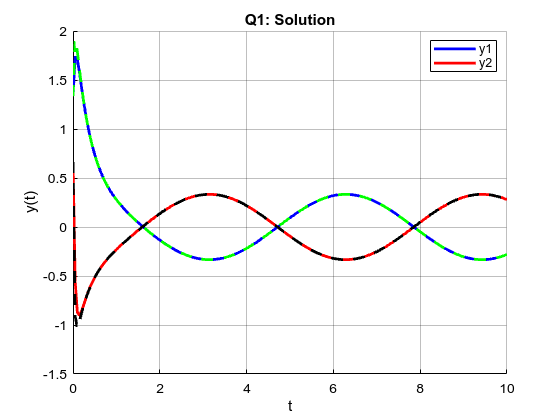

In [2]:
[t, Y] = runge_kutta_4(F1, initial_guess_1, ti, tf_1, step_size_1);

fprintf('Q1: h = %g, t = 0 to %g\n', step_size_1, tf_1);

figure('Color', 'w'); hold on; grid on;
set(gca, 'Color', 'w', 'XColor', 'k', 'YColor', 'k');
plot(t, Y(1,:), 'b-', 'LineWidth', 2);
plot(t, Y(2,:), 'r-', 'LineWidth', 2);
plot(t, exact1{1}(t), 'g--', 'LineWidth', 2);
plot(t, exact1{2}(t), 'k--', 'LineWidth', 2);
hold off; xlabel('t'); ylabel('y(t)');
title('Q1: Solution', 'Color', 'k');
legend('y1', 'y2', 'Location', 'best', 'TextColor', 'k', ...
    'Color', 'w', 'EdgeColor', 'k');

## Problem 2

Converged RK4 step size for Q2: h = 0.0312


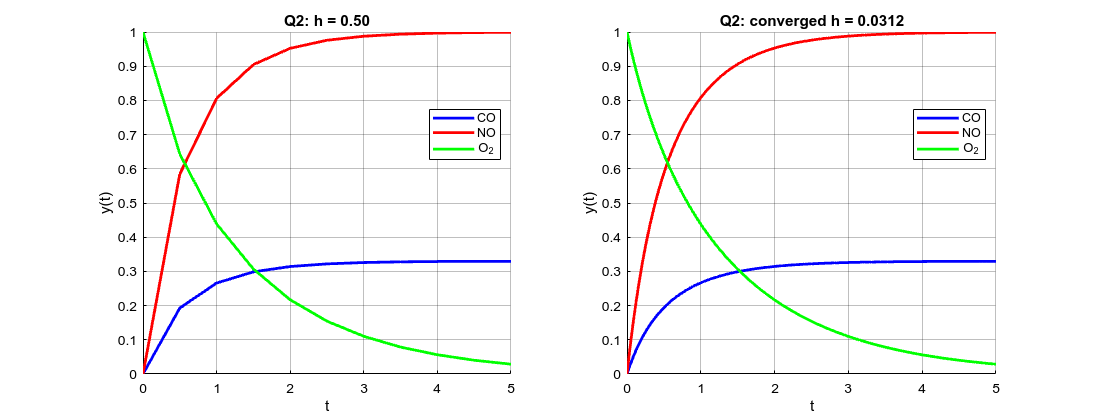

In [3]:
tol = 1e-8; h2 = step_size_2; prev_Y2 = inf;

while true
    [~, Y2] = runge_kutta_4(F2, initial_guess_2, ti, tf2, h2);
    final_diff2 = max(abs(Y2(:, end) - prev_Y2(:, end)));
    if final_diff2 < tol; break; end
    prev_Y2 = Y2; h2 = h2 / 2;
end

fprintf('Converged RK4 step size for Q2: h = %.4f\n', h2);
[t, Y2] = runge_kutta_4(F2, initial_guess_2, ti, tf2, h2);
[t_init, Y_init] = runge_kutta_4(F2, initial_guess_2, ti, ...
    tf2, step_size_2);

figure('Color', 'w', 'Position', [100, 100, 1100, 420]);
subplot(1,2,1); hold on; grid on;
set(gca, 'Color', 'w', 'XColor', 'k', 'YColor', 'k');
plot(t_init, Y_init(1,:), 'b-', 'LineWidth', 2); hold on;
plot(t_init, Y_init(2,:), 'r-', 'LineWidth', 2);
plot(t_init, Y_init(3,:), 'g-', 'LineWidth', 2);
hold off; xlabel('t'); ylabel('y(t)');
title(sprintf('Q2: h = %.2f', step_size_2), 'Color', 'k');
legend('CO', 'NO', 'O_2', 'Location', 'best', ...
    'TextColor', 'k', 'Color', 'w', 'EdgeColor', 'k');
grid on;

subplot(1,2,2); hold on; grid on;
set(gca, 'Color', 'w', 'XColor', 'k', 'YColor', 'k');
plot(t, Y2(1,:), 'b-', 'LineWidth', 2); hold on;
plot(t, Y2(2,:), 'r-', 'LineWidth', 2);
plot(t, Y2(3,:), 'g-', 'LineWidth', 2);
hold off; xlabel('t'); ylabel('y(t)');
title(sprintf('Q2: converged h = %.4f', h2), 'Color', 'k');
legend('CO', 'NO', 'O_2', 'Location', 'best', ...
    'TextColor', 'k', 'Color', 'w', 'EdgeColor', 'k');
grid on;

## Discussion

In problem 1, a system of two coupled ordinary differential equations is solved numerically
using the 4th-order Runge-Kutta (RK4) method. The initial conditions and parameters are
defined, and the solution is computed over time using a fixed step size. At each time step,
both the numerical and analytical solutions for $y_1(t)$ and $y_2(t)$ are calculated.
Finally, the results are visualized through plots and the final values from both methods are
printed for comparison to evaluate the accuracy of the numerical solution.

A similar thing was done in problem 2, but here we can obtain further information. At the reactor inlet, none of the $CO$ or $NO$ has reacted and $O_2$ is present at its full inlet value, so the initial condition is set as $y_1(0) = 0$, $y_2(0) = 0$ and $y_3(0) = 1$. As the dimensionless reactor length $t$ increases from 0 to 5, the coupled reaction terms $(1−y_1)(1−y_2)$ and $(1−y_1)y_3$ drive the system: $y_1$ and $y_2$ rise from zero as CO and NO are consumed, while $y_3$ falls from unity as $O_2$ is depleted.

To verify that the numerical solution is not sensitive to the chosen step size, the simulation was first performed with an initial step size h = 0.5, after which h was successively halved and the RK4 solution recomputed at each new step size. At every halving, the maximum absolute difference between the values of $y_1$, $y_2$ and $y_3$ at $t = 5$ obtained from the current and the previous step size was calculated.

The resulting conversion profiles of $y_1$ ($CO$), $y_2$ ($NO$) and $y_3$ ($O_2$) were plotted. All three curves display smooth, monotonic behaviour consistent with the underlying kinetics — $y_1$ and $y_2$ increase toward an asymptotic conversion as the t increases, while $y_3$ decreases correspondingly, reflecting the consumption of $O_2$ as the oxidation of CO and NO proceeds.